In [2]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib


Note: you may need to restart the kernel to use updated packages.


In [3]:
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import joblib


from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression


from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("All libraries Imported Successfully")

All libraries Imported Successfully


In [6]:
# LOAD DATASET from zip file 


zip_path = r"C:\Users\DELL\Downloads\logistic_reg\02_M2_EDA-20261005T165806Z-1-001.zip"

with zipfile.ZipFile(zip_path , "r")  as archive:
    csv_file = next (
        name for name in archive.namelist()
        if name.endswith("telco_with_ids.csv")
    )
    with archive.open(csv_file) as file:
        df = pd.read_csv(file)
print("Dataset loaded successfully !")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully !
Dataset shape: (7043, 24)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag,tenure_group,charges_group
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12,Low
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,0,25-36,Mid-Low
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12,Mid-Low
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,37-48,Mid-Low
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12,Mid-High


In [7]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [8]:
# Remove duplicate target and identifier/derived columns
drop_columns = [
    "customerID",
    "Churn",
    "tenure_group",
    "charges_group",
    "ChurnFlag"
]

X = df.drop(columns=drop_columns)
y = df["ChurnFlag"].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())

Feature shape: (7043, 19)
Target shape: (7043,)

Target classes:
ChurnFlag
0    5174
1    1869
Name: count, dtype: int64


In [10]:
numeric_features = X.select_dtypes(
     include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object" , "category" , "bool"]
).columns.tolist()

print("Numerical features"  , numeric_features)
print("Categorical features "  , categorical_features)

Numerical features ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features  ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [11]:
X_train , X_test , y_train , y_test = train_test_split(
    X,
    y,
    test_size = 0.20, 
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :" , len(X_test))

Training samples: 5634
Testing samples : 1409


In [17]:
numeric_transformer = Pipeline(steps=[
    ("imputer" , SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
    
])

categorical_tranformer = Pipeline(steps=[
    ("imputer" , SimpleImputer(strategy="most_frequent")), 
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers = [
        ("num" , numeric_transformer , numeric_features), 
        ("cat" , categorical_tranformer , categorical_features)
    ]
)

In [18]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [19]:
y_pred = model.predict(X_test)

# Probability that a customer belongs to the churn class
y_prob = model.predict_proba(X_test)[:, 1]

In [20]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

Accuracy:  0.7381
Precision: 0.5043
Recall:    0.7834
F1-score:  0.6136
ROC-AUC:   0.8415

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



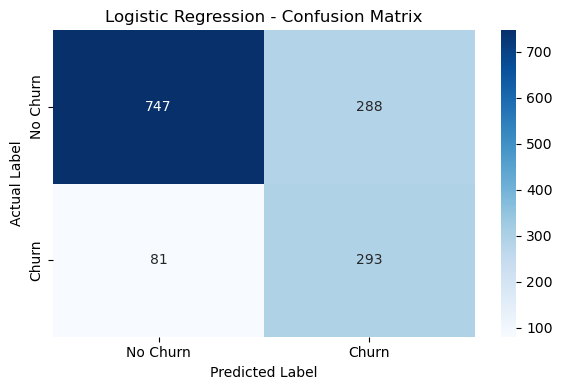

In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
model_path = "logistic_regression_model.pkl"

joblib.dump(model, model_path)

print(f"Model saved successfully as: {model_path}")

Model saved successfully as: logistic_regression_model.pkl


In [24]:
loaded_model = joblib.load(
    "logistic_regression_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [25]:
# Select one customer without using the target columns
sample_customer = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0, 1]

print("Predicted result:", "Churn" if prediction == 1 else "No Churn")
print(f"Churn probability: {probability:.2%}")

Predicted result: No Churn
Churn probability: 11.71%
